# Задача 2. PPO и Discrete SAC

Сравниваем PPO и Discrete SAC, каждый с памятью (GRU) и без неё (MLP), на четырёх средах.
Дополнительно — DSAC с обычной Q вместо мягкой (`soft_q=False`) на Env2 и Env4.
Все прогоны с одним сидом. Результаты: `outputs/task2/` (`runs/` — прогоны, `figures/`, `eval/`, `tables/`).

In [1]:
import csv
import json
import os
import sys
from pathlib import Path

# работаем из корня репозитория: там лежат src/ и outputs/
if Path.cwd().name == "tasks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
import numpy as np
import torch

from src import utils
from src.envs import load_mnist, make_env
from src.models import DSAC, PPO

In [2]:
# режим запуска: при обычном открытии ноутбука — полное обучение всех экспериментов и все графики
# на сервере скрипт задаёт переменные, чтобы запускать эксперименты параллельно
RUN_MODE = os.environ.get("RUN_MODE", "full")  # full или smoke (короткая проверка)
RUN_ONLY = os.environ.get("RUN_ONLY", "")  # имя одного эксперимента, пусто — все
RUN_STAGES = os.environ.get("RUN_STAGES", "train,plots").split(",")

torch.set_num_threads(1)  # прогоны идут параллельно, каждому хватит одного потока
CUDA = torch.cuda.is_available()
print("режим:", RUN_MODE, "| эксперимент:", RUN_ONLY or "все", "| этапы:", RUN_STAGES, "| CUDA:", CUDA)

режим: full | эксперимент: все | этапы: ['plots'] | CUDA: True


In [3]:
SETUPS = {
    1: dict(h=5, w=5, n_colors=None, obstacle_fraction=0.0),  # 25 уникальных цветов — полностью наблюдаемая
    2: dict(h=5, w=5, n_colors=5, obstacle_fraction=0.0),
    3: dict(h=10, w=10, n_colors=7, obstacle_fraction=0.1),
    4: dict(h=10, w=10, n_colors=4, obstacle_fraction=0.1),
}

## Гиперпараметры

In [4]:
ppo_cfg = {
    "device": "cpu",  # PPO на видеокарте не быстрее (замер: 479 против 429 шагов в секунду)
    "env_seed": 0,  # от него зависит карта
    "seed": 0,  # от него зависят сеть и старты эпизодов
    "memory": True,  # True — GRU, False — MLP без памяти
    "episodes_per_update": 10,  # сколько эпизодов собрать перед обновлением
    "epochs": 4,
    "episodes_per_batch": 5,
    "gamma": 0.99,
    "gae_lambda": 0.95,
    "lr": 3e-4,
    "clip": 0.2,
    "ent_coef": 0.01,
    "vf_coef": 0.5,
    "hidden": 128,
    "save_every": 50,  # как часто сохранять метрики и веса на диск
}

In [5]:
dsac_cfg = {
    "device": "cuda" if CUDA else "cpu",  # DSAC на видеокарте в 3 раза быстрее (167 против 52 шагов в секунду)
    "env_seed": 0,
    "seed": 0,
    "memory": True,
    "soft_q": True,  # мягкая Q (энтропия в цели критика) или обычная
    "buffer_episodes": 5000,  # сколько последних эпизодов помнить
    "learning_starts": 20,  # сколько эпизодов только копим опыт, не учась
    "updates_per_episode": 4,  # сколько обновлений после каждого эпизода
    "batch_size": 8,  # сколько случайных эпизодов из буфера в одном обновлении
    "gamma": 0.99,
    "tau": 0.005,  # скорость, с которой target-критики догоняют обычных
    "lr": 3e-4,
    "alpha": 0.005,  # температура: вес энтропии
    "hidden": 128,
    "save_every": 25,
}

In [6]:
# сколько эпизодов учиться: на больших картах дольше; smoke — короткая проверка, что всё работает
EPISODES = {
    "full": {"ppo": {1: 1000, 2: 1000, 3: 1500, 4: 1500}, "dsac": {1: 500, 2: 500, 3: 800, 4: 800}},
    "smoke": {"ppo": {1: 20, 2: 20, 3: 20, 4: 20}, "dsac": {1: 8, 2: 8, 3: 4, 4: 4}},
}
EVAL_EPISODES = {"full": 100, "smoke": 5}

# smoke-прогоны пишем отдельно, чтобы не смешать их с настоящими
OUT = "outputs/task2" if RUN_MODE == "full" else "runs/smoke/task2"

## Список экспериментов

In [7]:
EXPERIMENTS = []
for i in SETUPS:
    for memory in [True, False]:
        tag = "gru" if memory else "mlp"
        for algo, base in [("ppo", ppo_cfg), ("dsac", dsac_cfg)]:
            name = f"{algo}_env{i}_{tag}_seed0"
            cfg = {**base, **SETUPS[i], "memory": memory, "episodes": EPISODES[RUN_MODE][algo][i],
                   "budget": RUN_MODE, "out_dir": f"{OUT}/runs", "run_name": name}
            EXPERIMENTS.append({"name": name, "algo": algo, "cfg": cfg})

# требование задания: DSAC с обычной Q вместо мягкой
for i in [2, 4]:
    name = f"dsac_env{i}_gru_hardq_seed0"
    cfg = {**dsac_cfg, **SETUPS[i], "soft_q": False, "episodes": EPISODES[RUN_MODE]["dsac"][i],
           "budget": RUN_MODE, "out_dir": f"{OUT}/runs", "run_name": name}
    EXPERIMENTS.append({"name": name, "algo": "dsac", "cfg": cfg})

for exp in EXPERIMENTS:
    print(exp["name"], "эпизодов:", exp["cfg"]["episodes"], exp["cfg"]["device"])

ppo_env1_gru_seed0 эпизодов: 1000 cpu
dsac_env1_gru_seed0 эпизодов: 500 cuda
ppo_env1_mlp_seed0 эпизодов: 1000 cpu
dsac_env1_mlp_seed0 эпизодов: 500 cuda
ppo_env2_gru_seed0 эпизодов: 1000 cpu
dsac_env2_gru_seed0 эпизодов: 500 cuda
ppo_env2_mlp_seed0 эпизодов: 1000 cpu
dsac_env2_mlp_seed0 эпизодов: 500 cuda
ppo_env3_gru_seed0 эпизодов: 1500 cpu
dsac_env3_gru_seed0 эпизодов: 800 cuda
ppo_env3_mlp_seed0 эпизодов: 1500 cpu
dsac_env3_mlp_seed0 эпизодов: 800 cuda
ppo_env4_gru_seed0 эпизодов: 1500 cpu
dsac_env4_gru_seed0 эпизодов: 800 cuda
ppo_env4_mlp_seed0 эпизодов: 1500 cpu
dsac_env4_mlp_seed0 эпизодов: 800 cuda
dsac_env2_gru_hardq_seed0 эпизодов: 500 cuda
dsac_env4_gru_hardq_seed0 эпизодов: 800 cuda


## Обучение и оценка

Завершённые прогоны пропускаются, поэтому ячейку можно перезапускать.

In [8]:
def run_experiment(exp):
    # прогон, который уже закончился, второй раз не учим
    status_file = Path(OUT) / "runs" / exp["name"] / "status.json"
    if status_file.exists() and json.loads(status_file.read_text())["status"] == "completed":
        print("уже готово:", exp["name"])
        return

    if exp["algo"] == "ppo":
        alg = PPO(exp["cfg"])
    else:
        alg = DSAC(exp["cfg"])
    alg.train()

    # оценка на одних и тех же стартах (сиды 10000, 10001, ...): жадно и с сэмплированием действий
    n = EVAL_EPISODES[RUN_MODE]
    greedy = alg.evaluate(n, greedy=True)
    sampled = alg.evaluate(n, greedy=False)
    result = {"budget": RUN_MODE,
              "greedy": utils.eval_summary(greedy, alg.cfg["gamma"], alg.optimal),
              "stochastic": utils.eval_summary(sampled, alg.cfg["gamma"], alg.optimal)}
    utils.save_eval(alg.run_dir, result)

    s = result["stochastic"]
    title = f"{exp['name']}: успех {s['success_rate']:.2f}, длина {s['mean_length']:.1f} (оптимум {s['optimal_length']:.1f})"
    utils.save_eval_pictures(alg.env, sampled, Path(OUT) / "eval", exp["name"], title)

In [9]:
if "train" in RUN_STAGES:
    for exp in EXPERIMENTS:
        if RUN_ONLY == "" or RUN_ONLY == exp["name"]:
            run_experiment(exp)

## Графики обучения

Строятся по сохранённым `metrics.csv`, поэтому их можно перерисовать без обучения.

In [10]:
plt.style.use("seaborn-v0_8-darkgrid")


def load_metrics(run_path):
    # metrics.csv прогона: словарь {колонка: массив чисел}; None, если прогона нет
    path = Path(run_path) / "metrics.csv"
    if not path.exists():
        print("нет данных:", run_path)
        return None
    with open(path, encoding="utf-8") as f:
        rows = list(csv.DictReader(f))
    data = {}
    for key in rows[0]:
        values = [{"True": 1.0, "False": 0.0, "": np.nan}.get(row[key], row[key]) for row in rows]
        data[key] = np.array(values, dtype=float)
    return data

In [11]:
def plot_curve(ax, values, label, color, window=50):
    # линия — скользящее среднее за window эпизодов, полоса — скользящее стандартное отклонение
    # внутри одного прогона (у нас один сид, это не доверительный интервал)
    means = []
    stds = []
    for i in range(len(values)):
        last = values[max(0, i - window + 1):i + 1]
        last = last[~np.isnan(last)]
        means.append(np.mean(last) if len(last) > 0 else np.nan)
        stds.append(np.std(last) if len(last) > 0 else np.nan)
    means = np.array(means)
    stds = np.array(stds)
    ax.plot(means, color=color, linewidth=2, label=label)
    ax.fill_between(np.arange(len(values)), means - stds, means + stds, color=color, alpha=0.25)

In [12]:
def plot_compare(runs, labels, key, ylabel, filename):
    # runs: {"Env2": [путь1, путь2], ...} — на каждую среду свой график, на нём несколько прогонов
    colors = ["tab:red", "tab:blue", "tab:green"]
    fig, axes = plt.subplots(1, len(runs), figsize=(5.5 * len(runs), 4.3), squeeze=False)
    for ax, env_name in zip(axes[0], runs):
        for path, label, color in zip(runs[env_name], labels, colors):
            data = load_metrics(path)
            if data is not None:
                plot_curve(ax, data[key], label, color)
        ax.set_title(env_name)
        ax.set_xlabel("эпизод")
        ax.set_ylabel(ylabel)
        ax.legend(fontsize=8)
    Path(OUT, "figures").mkdir(parents=True, exist_ok=True)
    fig.savefig(Path(OUT) / "figures" / filename, dpi=150, bbox_inches="tight")
    plt.show()

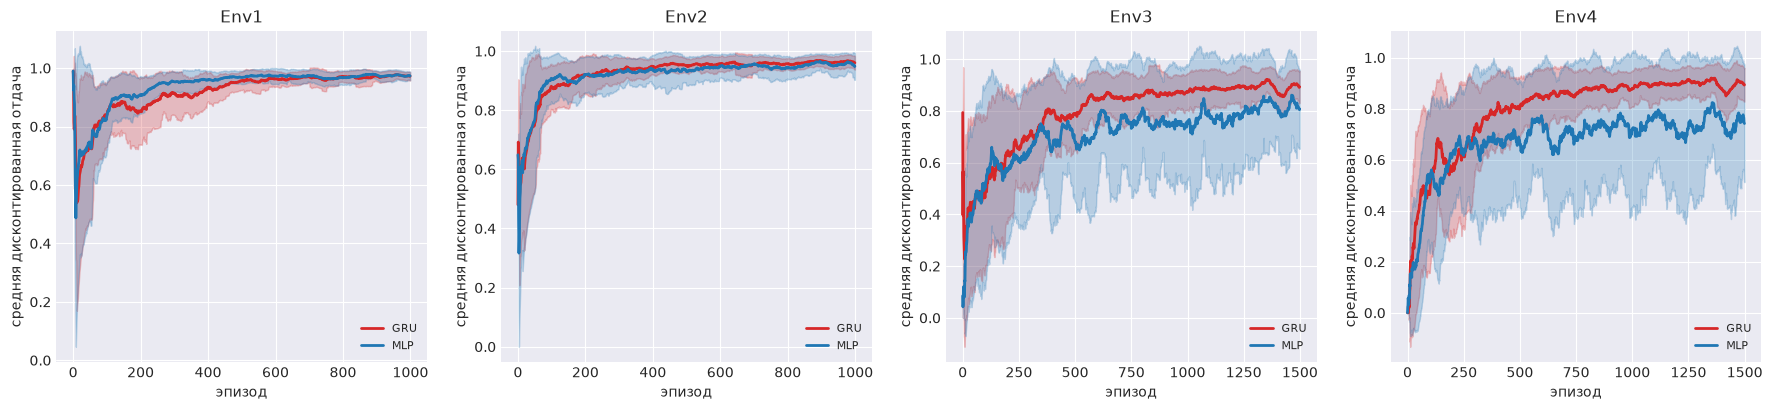

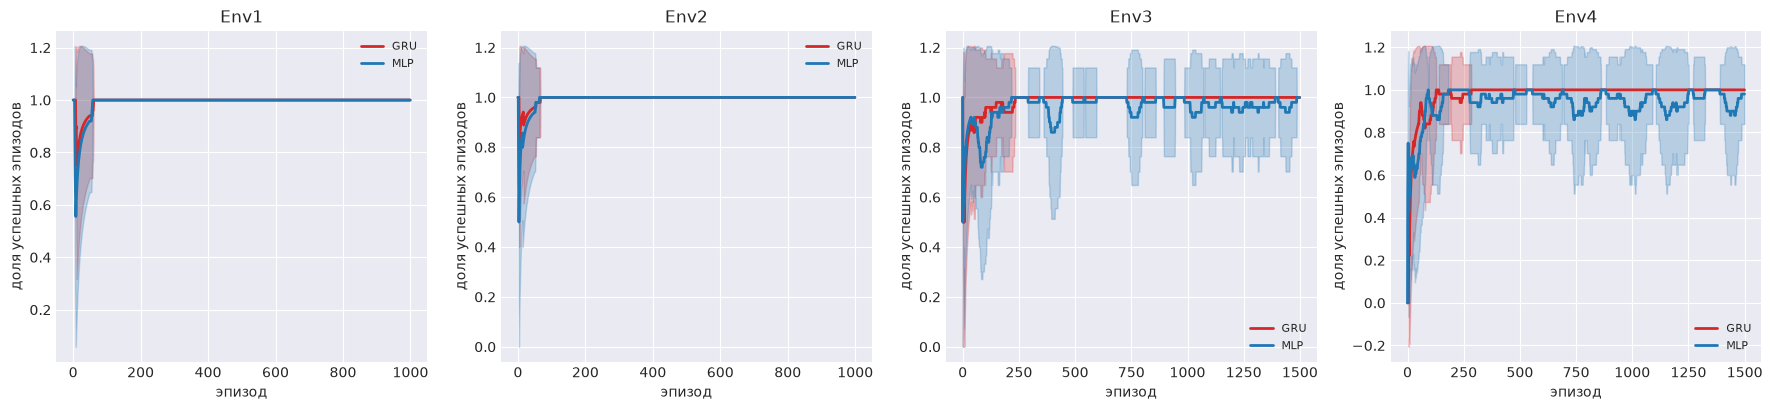

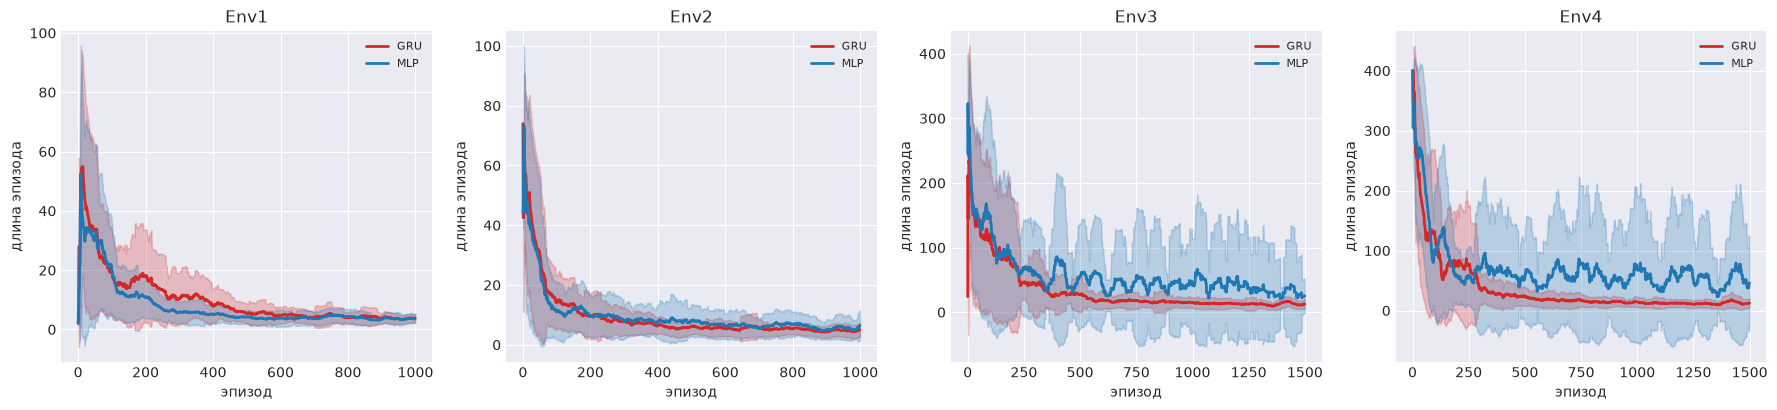

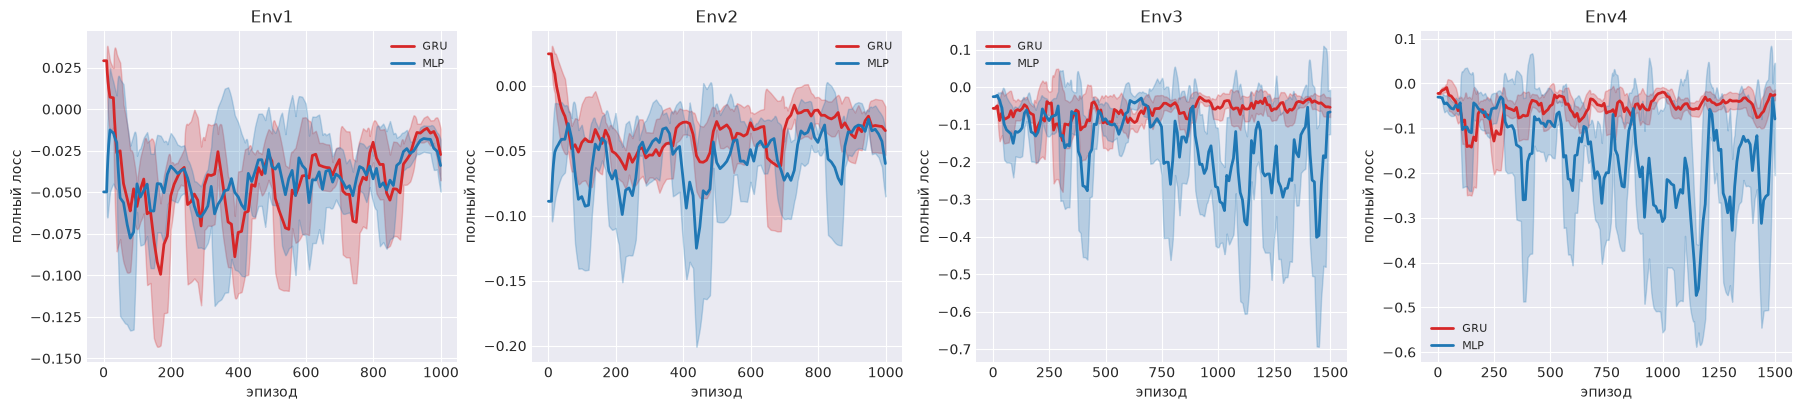

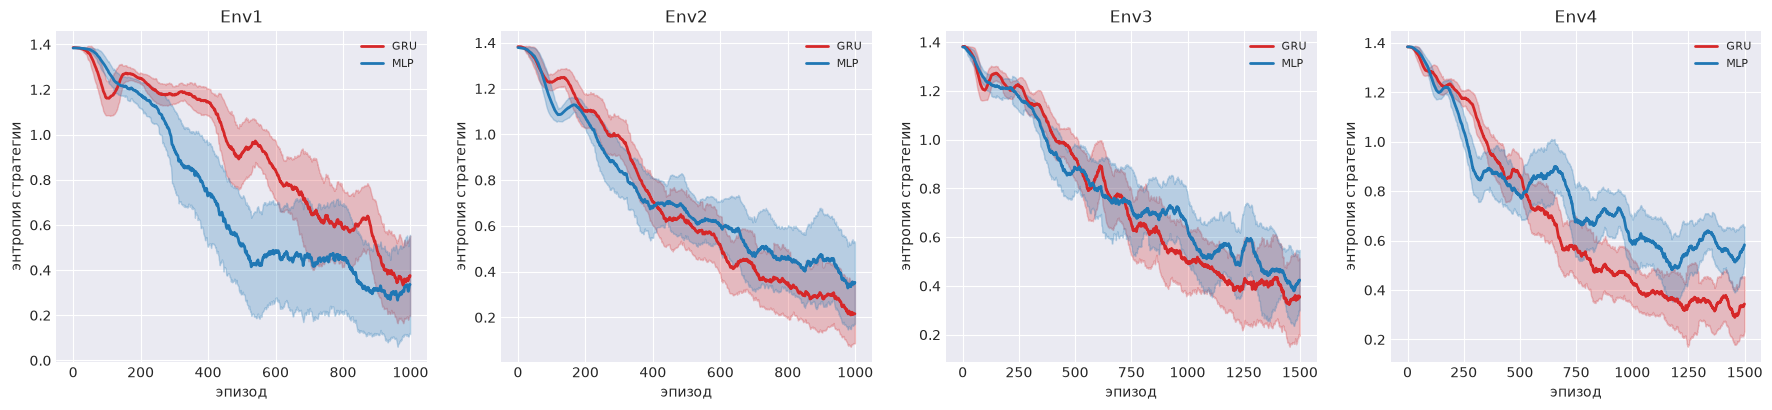

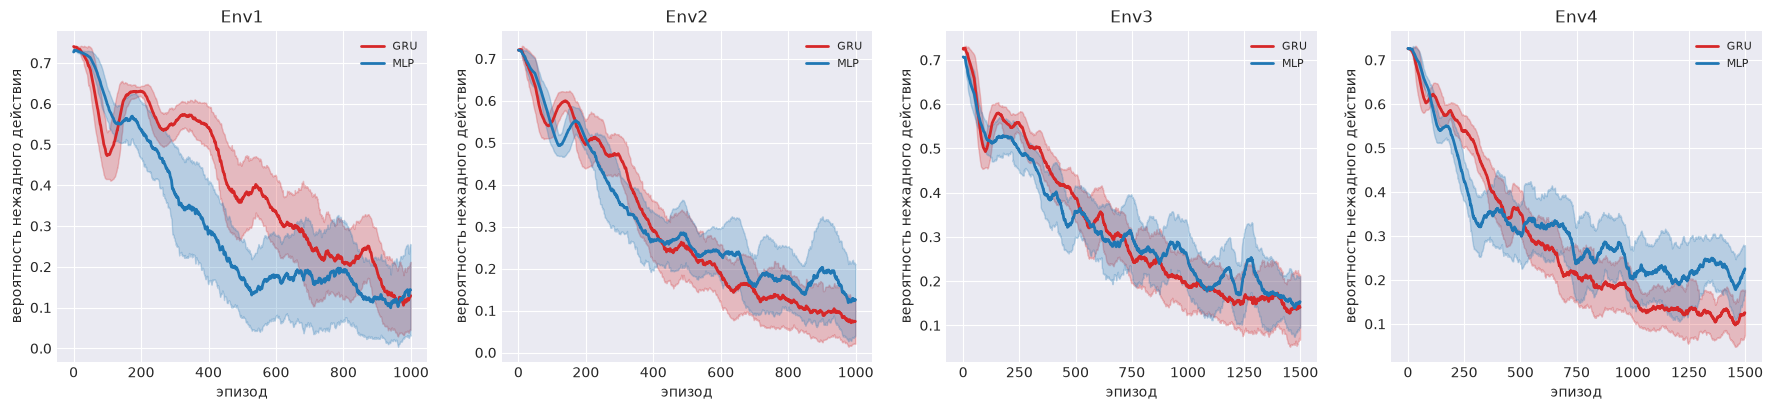

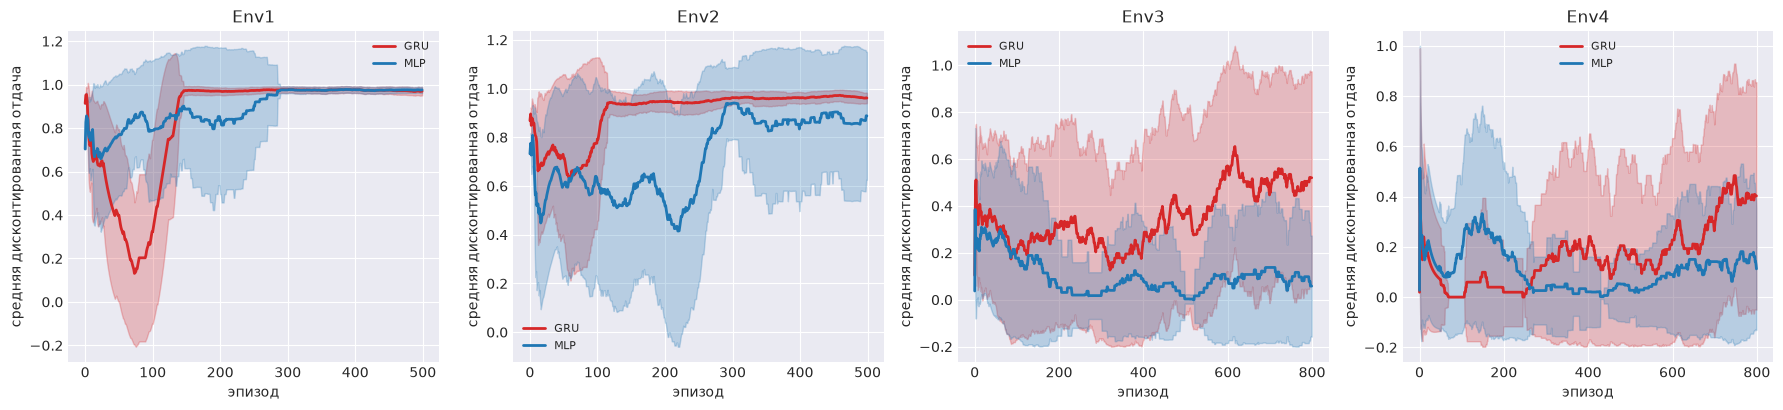

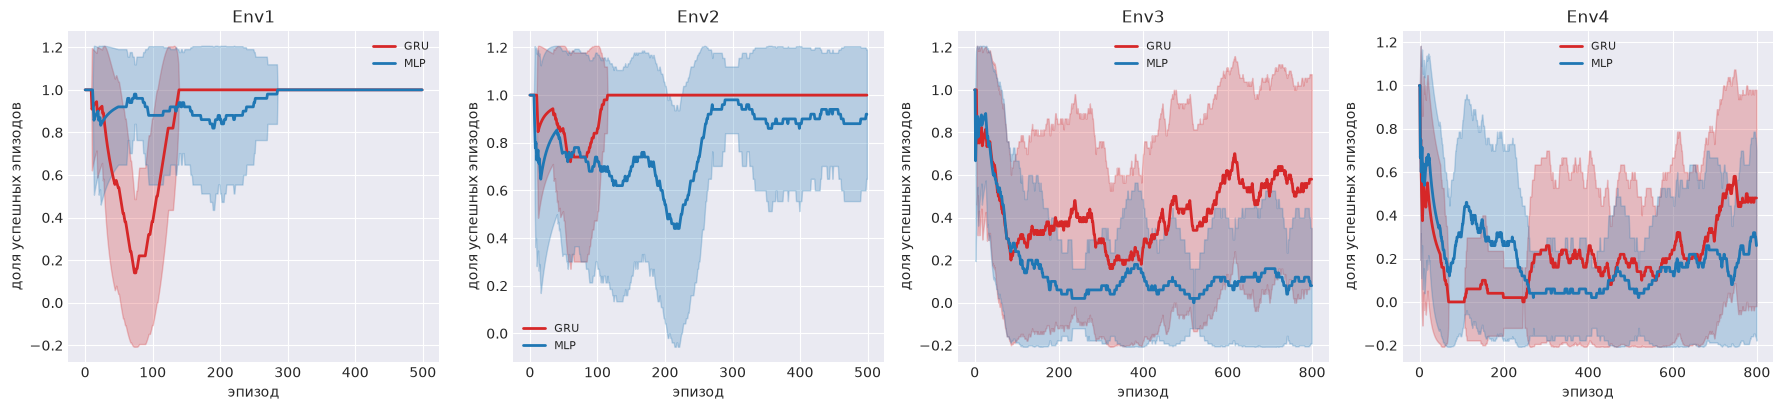

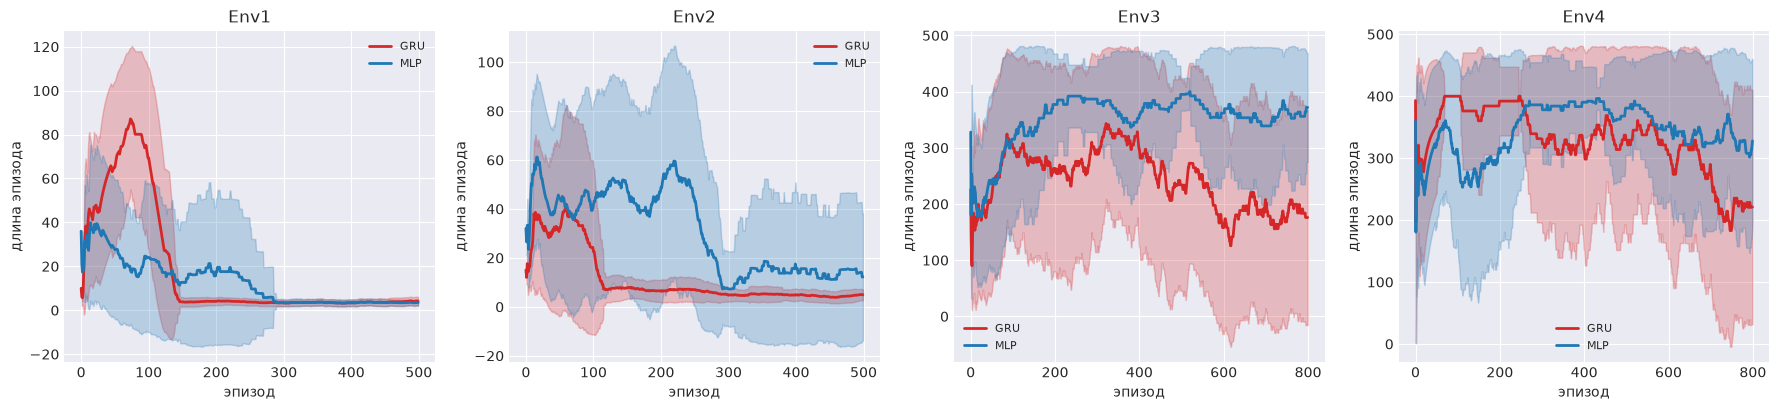

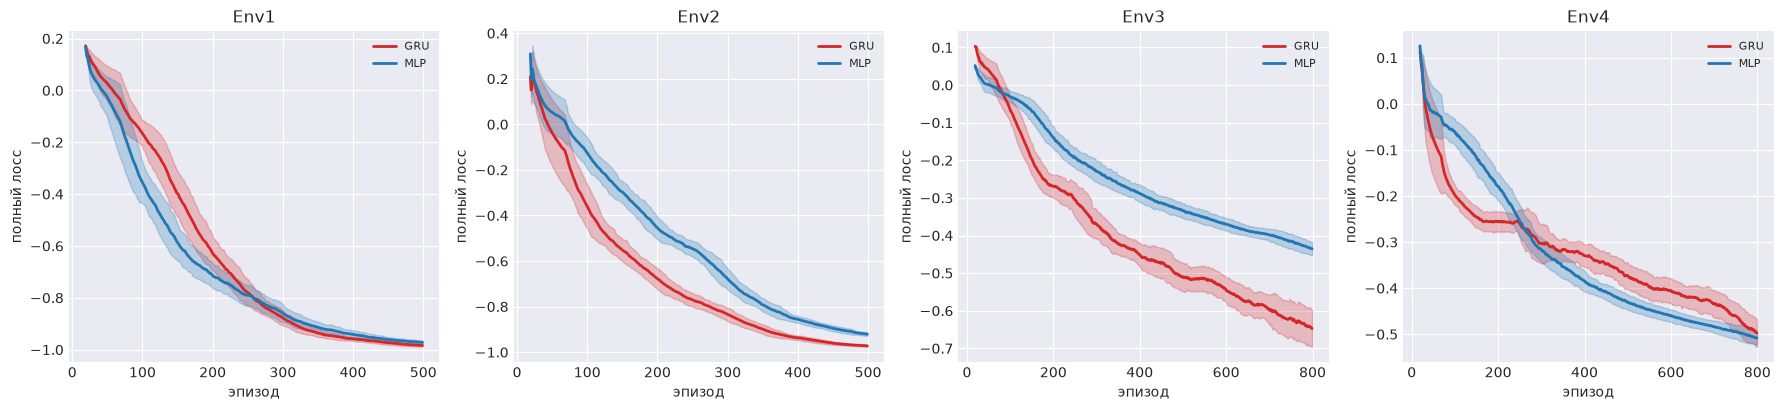

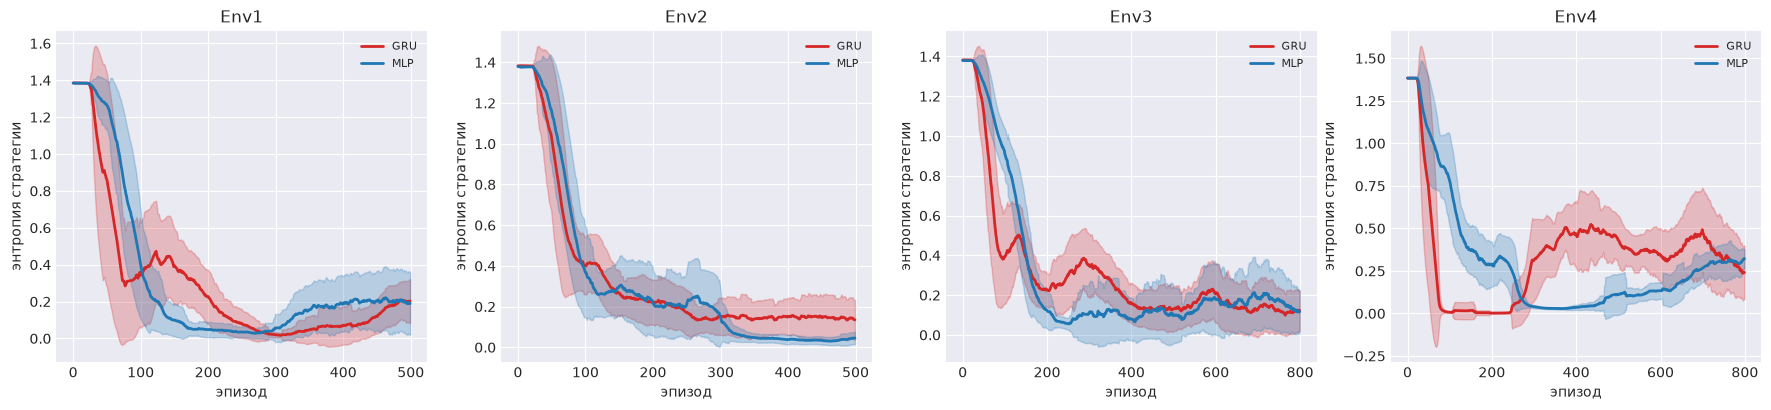

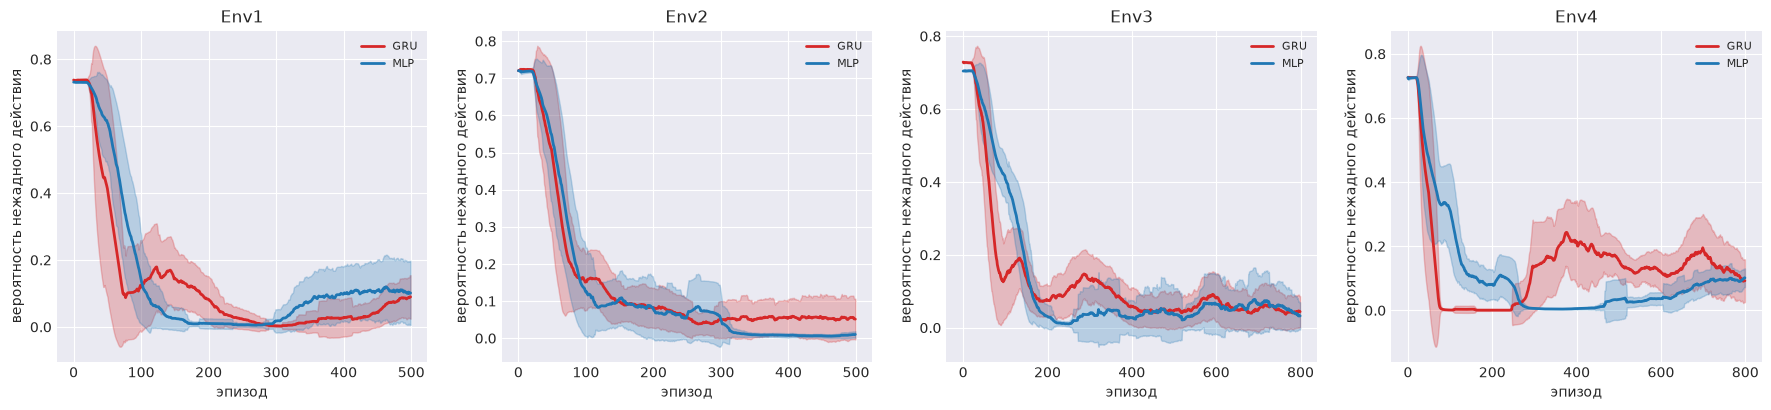

In [13]:
if "plots" in RUN_STAGES:
    metrics = [("return", "средняя дисконтированная отдача"), ("success", "доля успешных эпизодов"),
               ("length", "длина эпизода"), ("loss", "полный лосс"), ("entropy", "энтропия стратегии"),
               ("explore_prob", "вероятность нежадного действия")]
    for algo in ["ppo", "dsac"]:
        runs = {f"Env{i}": [f"{OUT}/runs/{algo}_env{i}_gru_seed0", f"{OUT}/runs/{algo}_env{i}_mlp_seed0"] for i in SETUPS}
        for key, ylabel in metrics:
            plot_compare(runs, ["GRU", "MLP"], key, ylabel, f"{algo}_{key}.png")

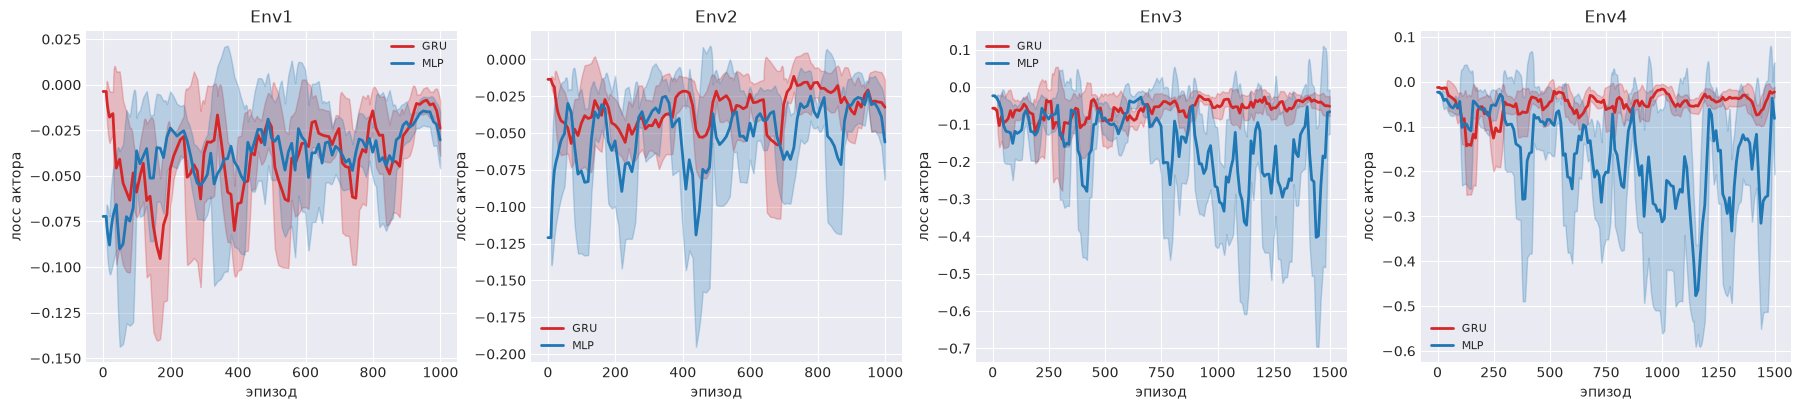

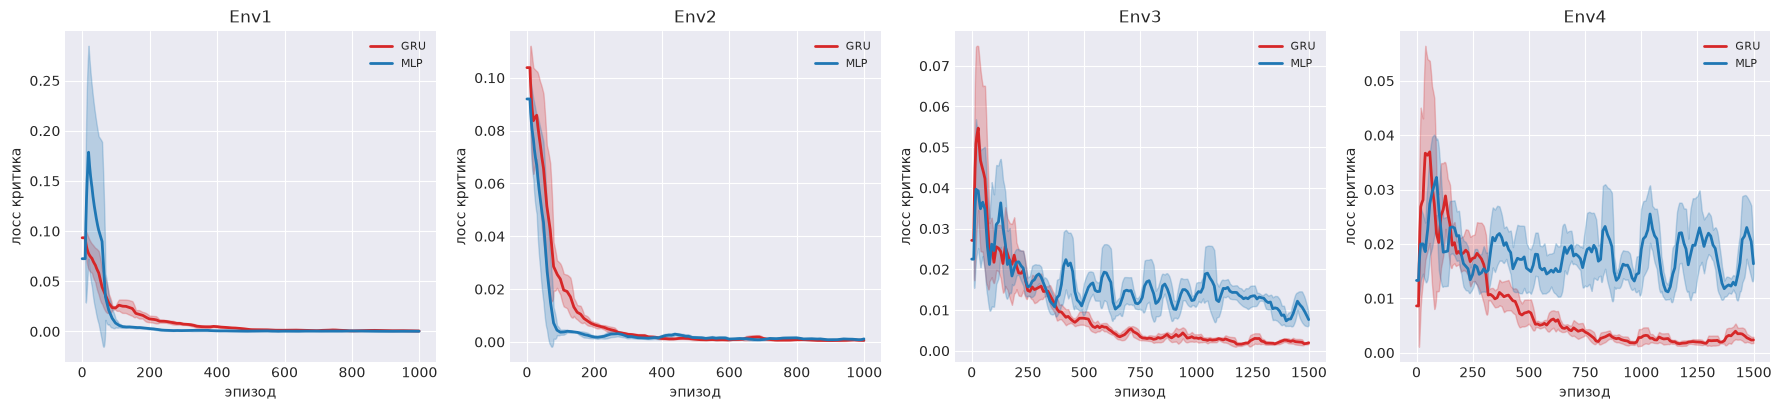

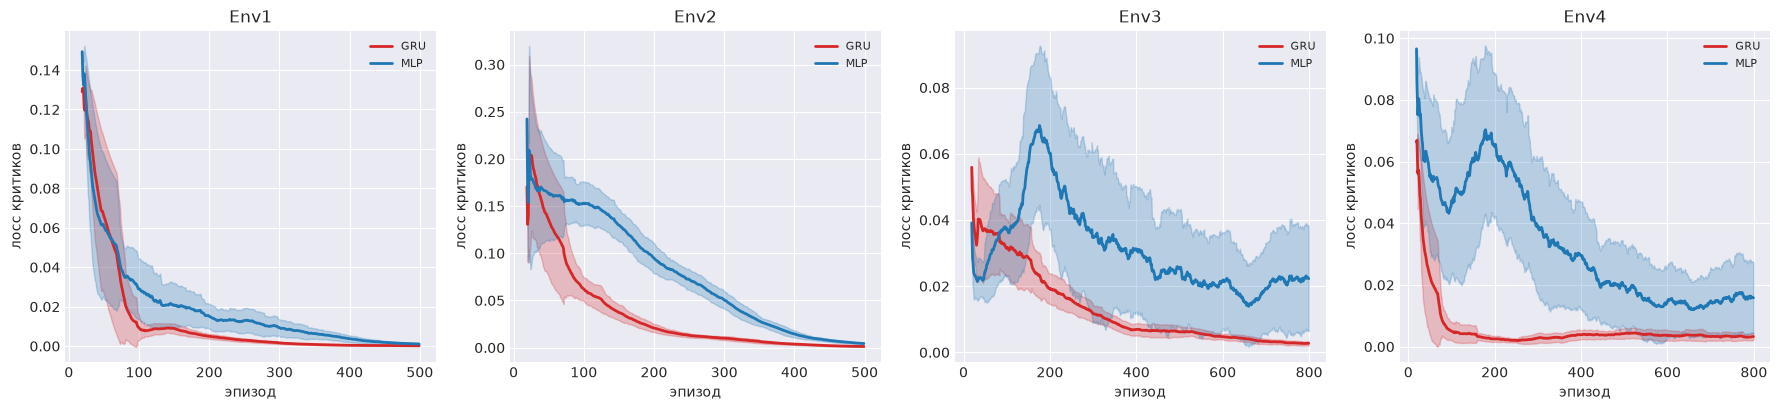

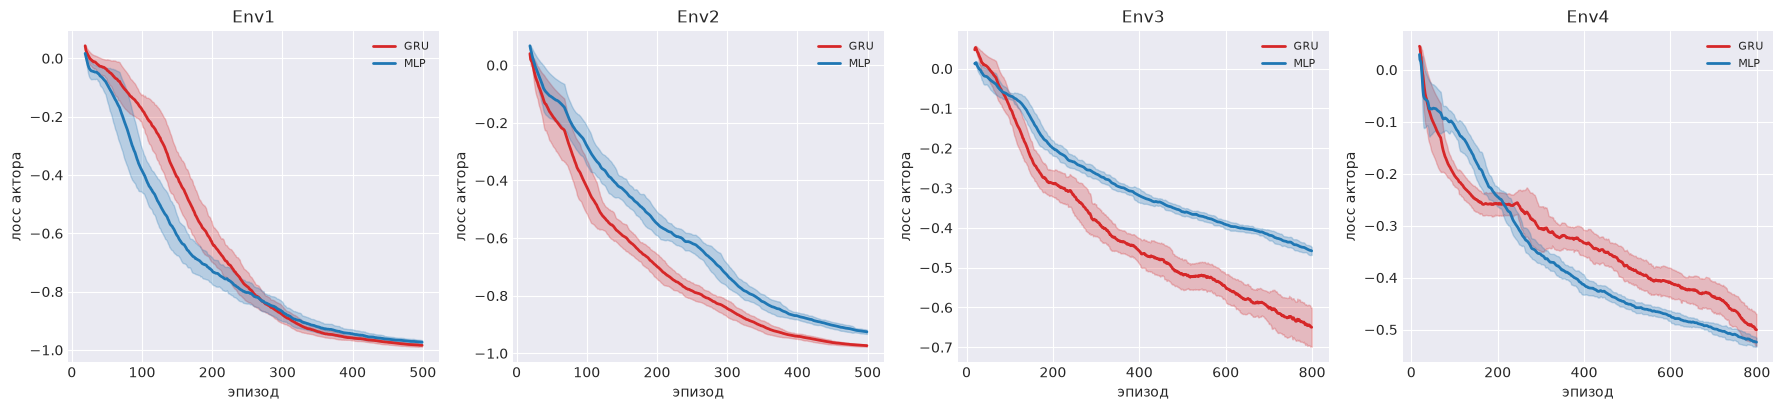

In [14]:
if "plots" in RUN_STAGES:
    # компоненты лосса
    runs = {f"Env{i}": [f"{OUT}/runs/ppo_env{i}_gru_seed0", f"{OUT}/runs/ppo_env{i}_mlp_seed0"] for i in SETUPS}
    plot_compare(runs, ["GRU", "MLP"], "policy_loss", "лосс актора", "ppo_policy_loss.png")
    plot_compare(runs, ["GRU", "MLP"], "value_loss", "лосс критика", "ppo_value_loss.png")
    runs = {f"Env{i}": [f"{OUT}/runs/dsac_env{i}_gru_seed0", f"{OUT}/runs/dsac_env{i}_mlp_seed0"] for i in SETUPS}
    plot_compare(runs, ["GRU", "MLP"], "q_loss", "лосс критиков", "dsac_q_loss.png")
    plot_compare(runs, ["GRU", "MLP"], "actor_loss", "лосс актора", "dsac_actor_loss.png")

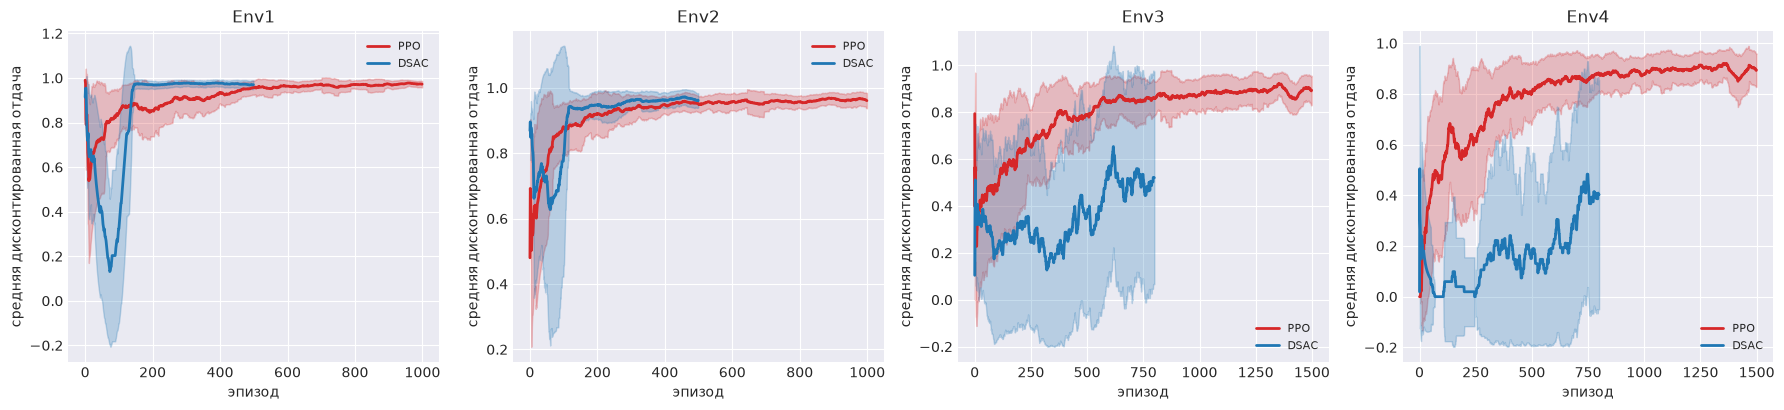

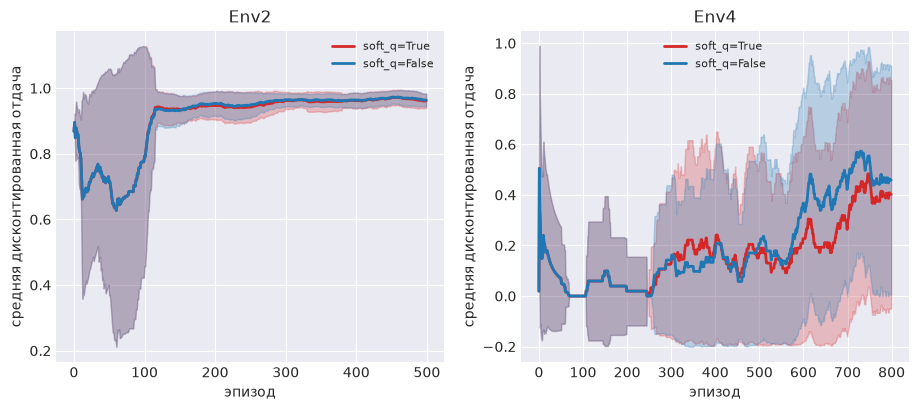

In [15]:
if "plots" in RUN_STAGES:
    # PPO против DSAC, оба с памятью
    runs = {f"Env{i}": [f"{OUT}/runs/ppo_env{i}_gru_seed0", f"{OUT}/runs/dsac_env{i}_gru_seed0"] for i in SETUPS}
    plot_compare(runs, ["PPO", "DSAC"], "return", "средняя дисконтированная отдача", "ppo_vs_dsac_return.png")
    # мягкая Q против обычной
    runs = {f"Env{i}": [f"{OUT}/runs/dsac_env{i}_gru_seed0", f"{OUT}/runs/dsac_env{i}_gru_hardq_seed0"] for i in [2, 4]}
    plot_compare(runs, ["soft_q=True", "soft_q=False"], "return", "средняя дисконтированная отдача", "dsac_soft_q_return.png")

## Итоговая оценка

100 эпизодов на одних и тех же стартах (сиды 10000–10099), жадно и с сэмплированием действий.
`optimal_length` — средняя длина пути у oracle с доступом к координатам.

In [16]:
def eval_rows(run_paths):
    # строки итоговой таблицы из eval.json прогонов
    rows = []
    for path in run_paths:
        eval_file = Path(path) / "eval.json"
        if not eval_file.exists():
            rows.append({"run": Path(path).name, "eval": "pending"})
            continue
        result = json.loads(eval_file.read_text(encoding="utf-8"))
        for mode in ["greedy", "stochastic"]:
            r = result[mode]
            rows.append({"run": Path(path).name, "eval": mode, "success_rate": round(r["success_rate"], 3),
                         "mean_return": round(r["mean_return"], 3), "mean_length": round(r["mean_length"], 1),
                         "failures": r["failures"], "optimal_length": round(r["optimal_length"], 2)})
    return rows


def save_table(rows, filename):
    Path(OUT, "tables").mkdir(parents=True, exist_ok=True)
    fields = ["run", "eval", "success_rate", "mean_return", "mean_length", "failures", "optimal_length"]
    with open(Path(OUT) / "tables" / filename, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)
    for row in rows:
        print(row)

In [17]:
if "plots" in RUN_STAGES:
    save_table(eval_rows([f"{OUT}/runs/{exp['name']}" for exp in EXPERIMENTS]), "eval_summary.csv")

{'run': 'ppo_env1_gru_seed0', 'eval': 'greedy', 'success_rate': 1.0, 'mean_return': 0.981, 'mean_length': 2.9, 'failures': 0, 'optimal_length': 3.33}
{'run': 'ppo_env1_gru_seed0', 'eval': 'stochastic', 'success_rate': 1.0, 'mean_return': 0.978, 'mean_length': 3.3, 'failures': 0, 'optimal_length': 3.33}
{'run': 'dsac_env1_gru_seed0', 'eval': 'greedy', 'success_rate': 1.0, 'mean_return': 0.979, 'mean_length': 3.1, 'failures': 0, 'optimal_length': 3.33}
{'run': 'dsac_env1_gru_seed0', 'eval': 'stochastic', 'success_rate': 1.0, 'mean_return': 0.979, 'mean_length': 3.2, 'failures': 0, 'optimal_length': 3.33}
{'run': 'ppo_env1_mlp_seed0', 'eval': 'greedy', 'success_rate': 1.0, 'mean_return': 0.981, 'mean_length': 2.9, 'failures': 0, 'optimal_length': 3.33}
{'run': 'ppo_env1_mlp_seed0', 'eval': 'stochastic', 'success_rate': 1.0, 'mean_return': 0.978, 'mean_length': 3.2, 'failures': 0, 'optimal_length': 3.33}
{'run': 'dsac_env1_mlp_seed0', 'eval': 'greedy', 'success_rate': 1.0, 'mean_return': 0